# Predicción de demanda intermitente a 2 semanas por código
### Proyecto final de Machine Learning · inventario y ventas de repuestos

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hector3008/proyecto-prediccion-demanda/blob/main/notebooks/proyecto_final.ipynb)

**Qué hace este notebook:** a partir de cortes (snapshots) diarios de inventario y ventas, predice cuántas unidades
se venderán de cada código en las **próximas 2 semanas**, compara modelos clásicos de demanda intermitente contra
modelos de Machine Learning (Ridge, Random Forest, XGBoost), optimiza hiperparámetros con validación temporal,
elige el modelo con criterio de negocio y explica sus decisiones con SHAP.

| # | Sección | Rúbrica |
|---|---|---|
| 1 | Formulación del problema | 1 |
| 2 | Análisis exploratorio (EDA) | 2 |
| 3 | Ingeniería de atributos | 3 |
| 4 | Entrenamiento con split train/validación | 4 |
| 5 | Optimización de hiperparámetros | 5 |
| 6 | Selección del modelo | 6 |
| 7 | Explicabilidad con SHAP | 7 |
| 8 | Conclusiones y limitaciones | 8 |

**Cómo ejecutarlo:** *Entorno de ejecución → Ejecutar todo* (Colab) o `jupyter nbconvert --execute` en local.
No requiere credenciales: lee `data/sample_snapshots.csv` (ver README). Toda la lógica reutilizable está en `src/`.

In [1]:
# ---- Configuración: rutas, dependencias y semilla (reproducibilidad) ----
import os, sys, subprocess, importlib, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

REPO_URL = "https://github.com/Hector3008/proyecto-prediccion-demanda.git"

def _raiz_repo():
    """Busca la raíz del repo; si se abre el notebook suelto en Colab, clona el repositorio."""
    for p in (Path.cwd(), Path.cwd().parent):
        if (p / "src" / "demanda.py").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "proyecto-prediccion-demanda"], check=True)
    return Path("proyecto-prediccion-demanda").resolve()

RAIZ = _raiz_repo()
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

# instala solo lo que falte (en Colab suele faltar shap)
for paquete in ("xgboost", "shap", "sklearn", "scipy"):
    try:
        importlib.import_module(paquete)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn" if paquete == "sklearn" else paquete], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.data import cargar_snapshots, agregar_columnas_derivadas, metadatos_codigo
from src.demanda import matriz_semanal, matriz_acumulada_semanal, clasificar_serie, ADI_CORTE, CV2_CORTE
from src.features import (construir_dataset, dividir_por_origen, FEATURES, NUM_COLS, CAT_COLS,
                          COLS_BL, H, MIN_SEM, ROT_ETQ)
from src.metricas import wape, sesgo, resumen, tabla_metricas, wape_scorer
from src import modelos as M

SEED = 42
np.random.seed(SEED)
DATA_PATH = os.environ.get("DATA_PATH", "data/sample_snapshots.csv")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11})
pd.set_option("display.max_columns", 40, "display.width", 160, "display.float_format", "{:,.3f}".format)
print("Repo:", RAIZ, "| datos:", DATA_PATH, "| semilla:", SEED)

Repo: /content/proyecto-prediccion-demanda | datos: data/sample_snapshots.csv | semilla: 42


## 1. Formulación del problema

**Contexto de negocio.** Una empresa importadora de repuestos maneja miles de códigos en dos almacenes (LV y SJL) y compra
con un *lead time* largo (≈45 días). Decidir cuánto pedir exige saber cuánto se venderá de cada código. El problema es
difícil porque la demanda es **intermitente**: la mayoría de códigos pasa semanas sin vender y luego vende en ráfagas.

**Tipo de problema:** **regresión** (la variable a predecir es una cantidad de unidades, no una clase).
Se descartó la clasificación (p. ej. "¿se agota en 45 días?") porque necesita una cantidad de pedido, no solo una alerta,
y porque con pocas semanas de historia (17 en la muestra real) no hay suficientes eventos de agotamiento para entrenarla de forma fiable.

| Elemento | Definición |
|---|---|
| **Unidad de análisis** | un código en un *origen* T (semana desde la cual se pronostica) |
| **Variable objetivo `y`** | unidades vendidas netas de devoluciones (`ventas − devolución`) en las **2 semanas siguientes** a T |
| **Variables predictoras** | solo información anterior a T (ver sección 3) |
| **Métrica principal** | **WAPE** = Σ\|predicción − real\| / Σ real |
| **Métricas de apoyo** | sesgo, faltante (demanda no cubierta), exceso (sobrestock) y cobertura |
| **Criterio de éxito** | un modelo de ML es útil solo si **supera al mejor modelo clásico** (Croston/SBA/TSB) en validación temporal, sin sesgo grande hacia la subestimación |

**Por qué WAPE.** MAPE no existe cuando la demanda real es 0 (frecuente aquí) y RMSE pesa de más los picos raros.
WAPE se calcula sobre unidades, pondera por volumen (un error en un código que vende mucho cuesta más compras mal hechas)
y se lee directo: *WAPE 0,40 = en promedio nos equivocamos por el 40% de lo que se vende*.

**Por qué 2 semanas.** Con pocas semanas de historial (17 en la muestra real), un horizonte mayor deja pocos orígenes para validar. El error a 2 semanas
mide cuán *estable y predecible* es la señal de cada código; no garantiza el error a 45 o 300 días (ver limitaciones, sección 8).

**Por qué importa el sesgo.** Subestimar produce quiebres de stock (ventas perdidas); sobrestimar inmoviliza capital.
Por eso, además de WAPE, se reportan *faltante* y *exceso* por separado.

## 2. Análisis exploratorio (EDA)

Cada gráfico va seguido de un *insight* calculado a partir de los datos (si cambia la muestra, el texto se recalcula).

In [2]:
# ---- 2.1 Carga, estructura, estadísticos y nulos ----
df_raw = cargar_snapshots(DATA_PATH)
df = agregar_columnas_derivadas(df_raw)
meta = metadatos_codigo(df)

print(f"Filas: {len(df):,} | códigos: {df['codigo'].nunique():,} | cortes: {df['fecha'].nunique()} "
      f"({df['fecha'].min():%d/%m/%Y} a {df['fecha'].max():%d/%m/%Y}) | marcas: {df['marca'].nunique()} | subfamilias: {df['subfamilia'].nunique()}")
display(df_raw.head())
print("\nEstadísticos de las columnas numéricas:")
display(df_raw.describe().T)

nulos = df_raw.isna().sum().to_frame("nulos"); nulos["%"] = 100 * nulos["nulos"] / len(df_raw)
print("\nValores nulos:"); display(nulos[nulos["nulos"] > 0] if (nulos["nulos"] > 0).any() else pd.DataFrame({"resultado": ["sin nulos"]}))

# los contadores son acumulados: ¿hay retrocesos (correcciones/reseteos)?
retro = {c: int((df.groupby("codigo")[c].diff() < 0).sum()) for c in ["ventas", "devolucion", "importacion"]}
print("Retrocesos en contadores acumulados (diferencias negativas entre cortes):", retro)
print("Stock total negativo:", int((df_raw["total"] < 0).sum()), "filas | códigos que aparecen tarde:",
      int((df.groupby("codigo")["fecha"].min() > df["fecha"].min()).sum()))

Filas: 56,856 | códigos: 600 | cortes: 96 (14/07/2026 a 16/11/2026) | marcas: 4 | subfamilias: 9


,codigo,fecha,marca,subfamilia,stock_lv,stock_sjl,total,ventas,devolucion,importacion,ajuste_lv,ajuste_sjl
0,COD-0001,2026-07-14,MARCA_A,SUBF_09,70.000,0,70.000,21.000,4.000,0.000,6.000,0.000
1,COD-0001,2026-07-21,MARCA_A,SUBF_09,70.000,0,70.000,21.000,4.000,0.000,6.000,0.000
2,COD-0001,2026-07-28,MARCA_A,SUBF_09,70.000,0,70.000,21.000,4.000,0.000,6.000,0.000
3,COD-0001,2026-08-04,MARCA_A,SUBF_09,70.000,0,70.000,21.000,4.000,0.000,6.000,0.000
4,COD-0001,2026-08-11,MARCA_A,SUBF_09,70.000,0,70.000,21.000,4.000,0.000,6.000,0.000



Estadísticos de las columnas numéricas:


,count,mean,min,25%,50%,75%,max,std
fecha,56856,2026-09-28 17:38:37.433516288,2026-07-14 00:00:00,2026-09-06 00:00:00,2026-09-30 00:00:00,2026-10-24 00:00:00,2026-11-16 00:00:00,NaN
stock_lv,"56,856.000",32.069,0.000,16.000,26.000,43.000,191.000,24.768
stock_sjl,"56,856.000",66.346,0.000,0.000,0.000,66.000,"5,732.000",253.668
total,"56,856.000",98.415,0.000,21.000,47.000,100.000,"5,864.000",261.352
ventas,"56,856.000",73.002,0.000,3.000,9.000,33.000,"2,258.000",210.898
devolucion,"56,856.000",0.632,-5.000,0.000,0.000,0.000,100.000,3.868
importacion,"56,713.000",59.340,0.000,0.000,0.000,40.000,"1,600.000",160.063
ajuste_lv,"56,856.000",0.467,-104.000,-2.000,0.000,1.000,250.000,21.856
ajuste_sjl,"56,856.000",9.680,"-1,952.000",0.000,0.000,0.000,"1,008.000",123.935



Valores nulos:


,nulos,%
importacion,143,0.252


Retrocesos en contadores acumulados (diferencias negativas entre cortes): {'ventas': 3, 'devolucion': 0, 'importacion': 1}
Stock total negativo: 0 filas | códigos que aparecen tarde: 11


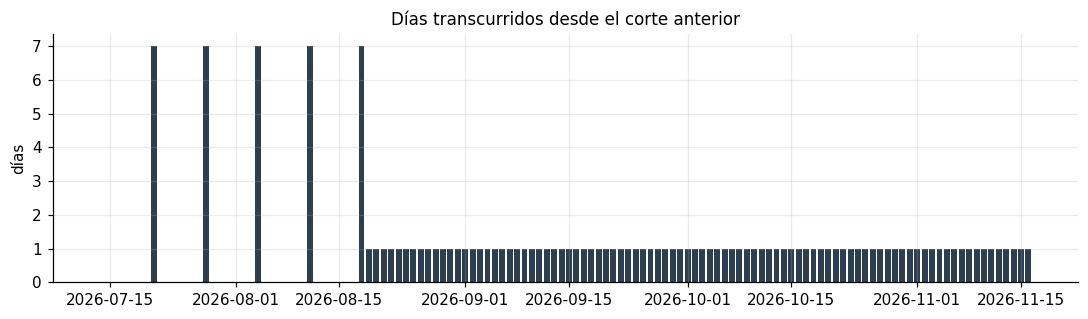

INSIGHT: el muestreo no es uniforme. Hasta el 18/08/2026 hay 5 cortes espaciados (mediana 7 días) y después 90 cortes diarios. Por eso la demanda se reconstruye interpolando el acumulado día a día y agregando por semana.


In [3]:
# ---- Gráfico 1: calendario de cortes (frecuencia de muestreo) ----
fechas = pd.Series(np.sort(df["fecha"].unique()))
saltos = fechas.diff().dt.days.fillna(0)
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(fechas, saltos, width=0.8, color="#2C3E50")
ax.set_title("Días transcurridos desde el corte anterior"); ax.set_ylabel("días")
plt.tight_layout(); plt.show()

esp = saltos[saltos > 1]
if len(esp):
    ult_esp = fechas[esp.index[-1]]
    print(f"INSIGHT: el muestreo no es uniforme. Hasta el {ult_esp:%d/%m/%Y} hay {len(esp)} cortes espaciados "
          f"(mediana {int(esp.median())} días) y después {int((fechas > ult_esp).sum())} cortes diarios. "
          "Por eso la demanda se reconstruye interpolando el acumulado día a día y agregando por semana.")
else:
    print("INSIGHT: los cortes son diarios y consecutivos.")

Matriz semanal: 600 códigos × 17 semanas | celdas observadas: 10,050
Semanas con demanda negativa (devoluciones > ventas): 20 -> se recortan a 0 al construir las series (no es demanda).


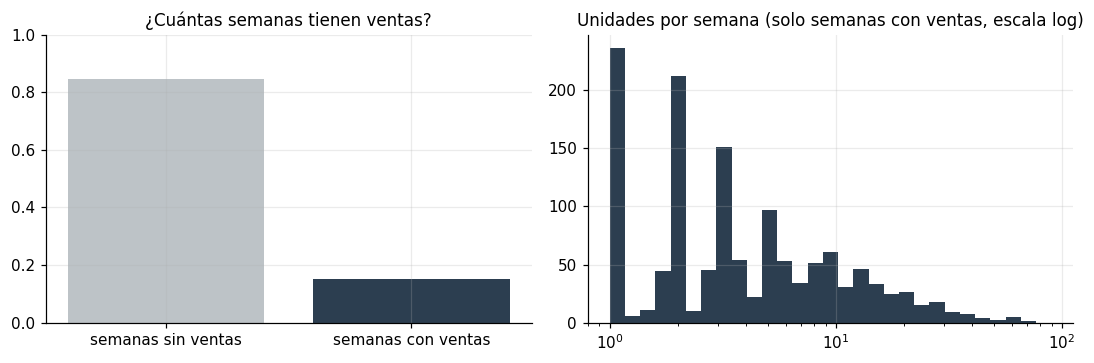

INSIGHT: 85% de las semanas código-semana no tiene ventas; cuando hay ventas, la mediana es 3 u. y el promedio 5.4 u. (promedio >> mediana: cola larga de picos). Un modelo que prediga el promedio fallará casi siempre; esto es demanda intermitente.


In [4]:
# ---- Matriz semanal de demanda (código × semana) ----
mat = matriz_semanal(df)                       # NaN = el código aún no tenía datos
cum_stock = matriz_acumulada_semanal(df, "total")
semanas = mat.shape[1]
valores = mat.stack()                          # todas las celdas código-semana observadas
print(f"Matriz semanal: {mat.shape[0]} códigos × {semanas} semanas | celdas observadas: {len(valores):,}")
print(f"Semanas con demanda negativa (devoluciones > ventas): {int((valores < 0).sum())} "
      f"-> se recortan a 0 al construir las series (no es demanda).")

# ---- Gráfico 2: distribución de la demanda semanal ----
pos = valores[valores > 0]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(["semanas sin ventas", "semanas con ventas"], [(valores <= 0).mean(), (valores > 0).mean()], color=["#BDC3C7", "#2C3E50"])
ax[0].set_title("¿Cuántas semanas tienen ventas?"); ax[0].set_ylim(0, 1)
ax[1].hist(pos, bins=np.logspace(0, np.log10(max(pos.max(), 10)), 30), color="#2C3E50")
ax[1].set_xscale("log"); ax[1].set_title("Unidades por semana (solo semanas con ventas, escala log)")
plt.tight_layout(); plt.show()
print(f"INSIGHT: {(valores <= 0).mean():.0%} de las semanas código-semana no tiene ventas; cuando hay ventas, la mediana es "
      f"{pos.median():.0f} u. y el promedio {pos.mean():.1f} u. (promedio >> mediana: cola larga de picos). "
      "Un modelo que prediga el promedio fallará casi siempre; esto es demanda intermitente.")

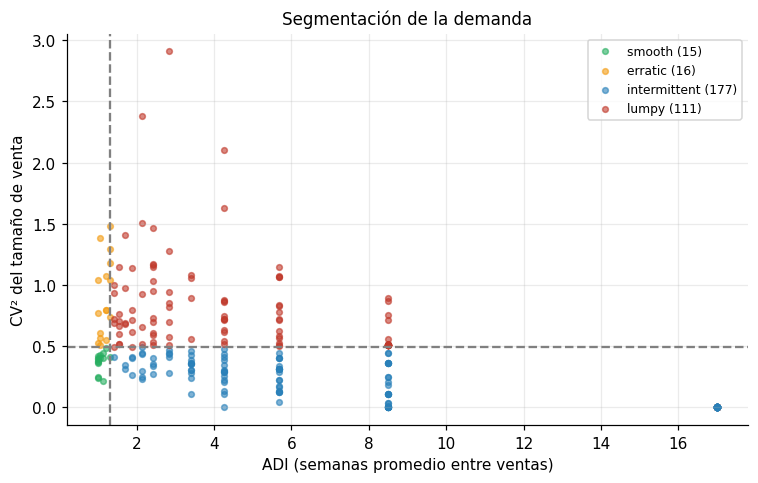

INSIGHT: de 600 códigos, 273 no vendieron nada; entre los 327 con ventas, 88% es intermitente o irregular (ADI ≥ 1.32). Para estos códigos los modelos de series de tiempo clásicos suelen ser difíciles de superar.


In [5]:
# ---- Gráfico 3: clasificación ADI / CV² (Syntetos-Boylan) ----
filas = []
for cod, fila in mat.iterrows():
    v = fila.dropna().clip(lower=0).to_numpy()
    adi, cv2, seg = clasificar_serie(v, MIN_SEM)
    filas.append((cod, adi, cv2, seg, v.sum()))
seg_full = pd.DataFrame(filas, columns=["codigo", "adi", "cv2", "segmento", "total"]).set_index("codigo")

colores = {"smooth": "#27AE60", "erratic": "#F39C12", "intermittent": "#2980B9", "lumpy": "#C0392B"}
fig, ax = plt.subplots(figsize=(7, 4.5))
for s, c in colores.items():
    g = seg_full[seg_full["segmento"] == s]
    ax.scatter(g["adi"], g["cv2"], s=14, alpha=.6, color=c, label=f"{s} ({len(g)})")
ax.axvline(ADI_CORTE, color="gray", ls="--"); ax.axhline(CV2_CORTE, color="gray", ls="--")
ax.set_xlabel("ADI (semanas promedio entre ventas)"); ax.set_ylabel("CV² del tamaño de venta")
ax.set_title("Segmentación de la demanda"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
cuenta = seg_full["segmento"].value_counts()
con_ventas = (seg_full["segmento"] != "sin_ventas").sum()
irreg = cuenta.get("intermittent", 0) + cuenta.get("lumpy", 0)
print(f"INSIGHT: de {len(seg_full)} códigos, {cuenta.get('sin_ventas', 0)} no vendieron nada; entre los {con_ventas} con ventas, "
      f"{irreg / max(con_ventas, 1):.0%} es intermitente o irregular (ADI ≥ {ADI_CORTE}). "
      "Para estos códigos los modelos de series de tiempo clásicos suelen ser difíciles de superar.")

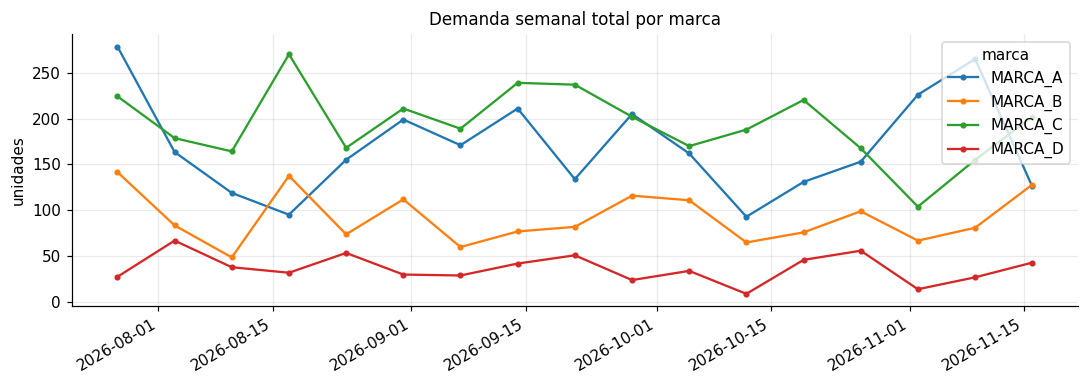

INSIGHT: la marca MARCA_C concentra 39% de las unidades. Comparando la 2ª mitad del periodo con la 1ª, la variación del nivel por marca va de -15% (MARCA_D) a -0% (MARCA_B). El nivel de demanda cambia entre periodos: por eso la validación debe ser temporal.


In [6]:
# ---- Gráfico 4: demanda semanal por marca ----
por_marca = mat.clip(lower=0).join(meta["marca"]).groupby("marca").sum(min_count=1).T
fig, ax = plt.subplots(figsize=(10, 3.6))
por_marca.plot(ax=ax, marker="o", ms=3)
ax.set_title("Demanda semanal total por marca"); ax.set_ylabel("unidades"); ax.set_xlabel("")
plt.tight_layout(); plt.show()
tot_marca = por_marca.sum().sort_values(ascending=False)
mitad = semanas // 2
camb = (por_marca.iloc[mitad:].mean() / por_marca.iloc[:mitad].mean() - 1).sort_values()
print(f"INSIGHT: la marca {tot_marca.index[0]} concentra {tot_marca.iloc[0] / tot_marca.sum():.0%} de las unidades. "
      f"Comparando la 2ª mitad del periodo con la 1ª, la variación del nivel por marca va de {camb.iloc[0]:+.0%} ({camb.index[0]}) a {camb.iloc[-1]:+.0%} ({camb.index[-1]}). "
      + ("El nivel de demanda cambia entre periodos: por eso la validación debe ser temporal."
         if camb.abs().max() >= 0.15 else
         "El nivel por marca es relativamente estable entre mitades; aun así se valida en el tiempo, porque un split aleatorio filtraría el futuro."))

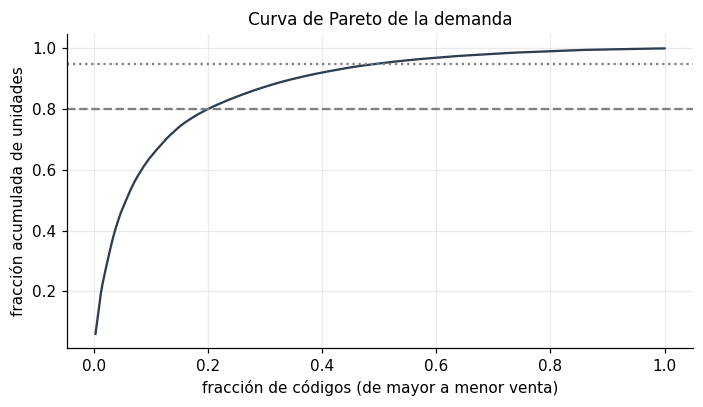

INSIGHT: el 20% de los códigos con ventas (64) explica el 80% de las unidades. El error del modelo en pocos códigos de alta rotación pesa más que en cientos de códigos casi sin ventas: justifica WAPE (ponderado por volumen).


In [7]:
# ---- Gráfico 5: concentración de la demanda (Pareto / ABC) ----
tot_cod = mat.clip(lower=0).sum(axis=1).sort_values(ascending=False)
tot_cod = tot_cod[tot_cod > 0]
acum = tot_cod.cumsum() / tot_cod.sum()
x = np.arange(1, len(acum) + 1) / len(acum)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(x, acum.values, color="#2C3E50"); ax.axhline(0.8, color="gray", ls="--"); ax.axhline(0.95, color="gray", ls=":")
ax.set_xlabel("fracción de códigos (de mayor a menor venta)"); ax.set_ylabel("fracción acumulada de unidades")
ax.set_title("Curva de Pareto de la demanda")
plt.tight_layout(); plt.show()
n80 = int((acum <= 0.8).sum()) + 1
print(f"INSIGHT: el {n80 / len(tot_cod):.0%} de los códigos con ventas ({n80}) explica el 80% de las unidades. "
      "El error del modelo en pocos códigos de alta rotación pesa más que en cientos de códigos casi sin ventas: justifica WAPE (ponderado por volumen).")

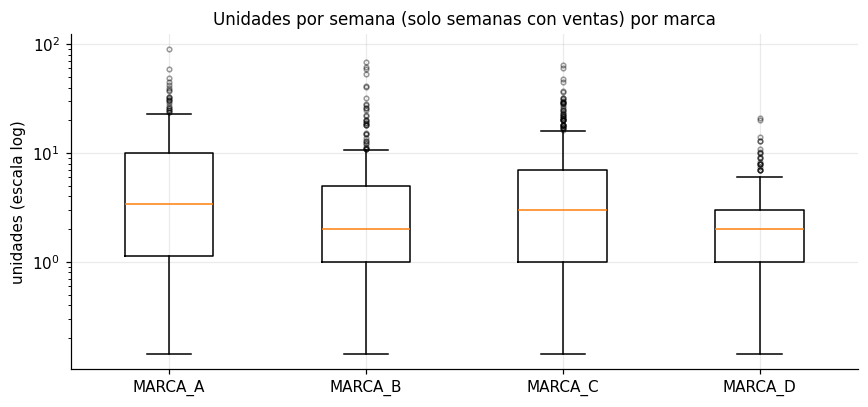

INSIGHT: con la regla de Tukey (> 14 u./semana) hay 147 observaciones atípicas (9.6% de las semanas con ventas). El mayor pico es 90 u. (COD-0437). Mayores picos:


,codigo,marca,u
7332,COD-0437,MARCA_A,89.571
7426,COD-0442,MARCA_B,69.000
6215,COD-0370,MARCA_C,64.000
7420,COD-0442,MARCA_B,61.286
8336,COD-0498,MARCA_C,60.000


DECISIÓN: no se eliminan. Son ventas reales (pedidos grandes) que el negocio necesita anticipar; se manejan con modelos robustos (árboles, objetivo de error absoluto en XGBoost) y con una métrica ponderada por volumen.


In [8]:
# ---- Gráfico 6: outliers (boxplot por marca + regla de Tukey) ----
nz = mat.clip(lower=0).stack().rename("u").reset_index()
nz.columns = ["codigo", "semana", "u"]
nz = nz[nz["u"] > 0].join(meta["marca"], on="codigo")
marcas = sorted(nz["marca"].dropna().unique())
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.boxplot([nz.loc[nz["marca"] == m, "u"] for m in marcas], tick_labels=marcas, flierprops={"markersize": 3, "alpha": .4})
ax.set_yscale("log"); ax.set_title("Unidades por semana (solo semanas con ventas) por marca"); ax.set_ylabel("unidades (escala log)")
plt.tight_layout(); plt.show()

q1, q3 = nz["u"].quantile([.25, .75]); lim = q3 + 1.5 * (q3 - q1)
out = nz[nz["u"] > lim].sort_values("u", ascending=False)
print(f"INSIGHT: con la regla de Tukey (> {lim:.0f} u./semana) hay {len(out)} observaciones atípicas ({len(out) / len(nz):.1%} de las semanas con ventas). "
      f"El mayor pico es {out['u'].iloc[0]:.0f} u. ({out['codigo'].iloc[0]}). Mayores picos:")
display(out.head(5)[["codigo", "marca", "u"]])
print("DECISIÓN: no se eliminan. Son ventas reales (pedidos grandes) que el negocio necesita anticipar; se manejan con "
      "modelos robustos (árboles, objetivo de error absoluto en XGBoost) y con una métrica ponderada por volumen.")

## 3. Ingeniería de atributos

Todo se calcula con **datos anteriores al origen T** (nada del futuro). La serie semanal se obtiene del acumulado
`ventas − devolución` interpolado (sección 2). Cada variable tiene una razón de negocio:

| Grupo | Variables | Justificación |
|---|---|---|
| Memoria reciente | `lag1`, `lag2`, `lag3`, `media_ult3` | lo vendido hace poco es el mejor predictor de lo próximo |
| Nivel y variabilidad | `media`, `desv`, `maximo`, `n_sem` | escala del código y confianza (más semanas = más información) |
| Intermitencia | `frac_semanas_con_venta`, `semanas_desde_ult_venta`, `adi`, `cv2` | miden *cuán a menudo* y *cuán irregular* se vende; base de la clasificación Syntetos-Boylan |
| Tendencia | `tendencia` (media últimas 2 − media anteriores) | detecta códigos que aceleran o se apagan |
| Inventario | `stock`, `cobertura_sem` (stock / venta media, tope 52), `agotado` | un código agotado vende menos de lo que se demandaría (demanda censurada) |
| Categóricas | `marca`, `subfamilia`, `segmento` (ADI/CV²), `rotacion` (cuartil de venta media) | comportamiento común dentro de cada grupo |

**Transformaciones (aplicadas dentro de un `Pipeline`, ajustadas solo con el train de cada fold):**
imputación por mediana (stock faltante en códigos nuevos), `StandardScaler` (necesario para la penalización L2 de Ridge,
inocuo para árboles) y `OneHotEncoder(handle_unknown="ignore")` para las categóricas (sin orden natural; tolera categorías nuevas).
La variable objetivo **no se transforma**: WAPE se mide en unidades y un `log1p` sesgaría las predicciones a la baja (más quiebres).

Además se guardan, para cada fila, las predicciones de los modelos clásicos (`bl_*`: Croston, SBA, TSB, SES, MA4, promedio),
calculadas solo con la historia previa a T. Sirven como **baselines** y como referencia comparable.

In [9]:
# ---- Dataset supervisado: una fila por (código, origen T) ----
dataset = construir_dataset(mat, cum_stock, meta, h=H, min_sem=MIN_SEM)
print(f"Dataset: {dataset.shape[0]:,} filas × {dataset.shape[1]} columnas | códigos: {dataset['codigo'].nunique()} | orígenes T: {[int(t) for t in sorted(dataset['T'].unique())]}")
display(dataset[["codigo", "T", "y"] + NUM_COLS[:8] + CAT_COLS].head())

# ---- Prueba anti-fuga: las variables de la fila T deben salir de las semanas < T ----
rng = np.random.default_rng(SEED)
for i in rng.choice(len(dataset), 200, replace=False):
    f = dataset.iloc[i]
    serie = mat.loc[f["codigo"]].clip(lower=0)
    assert np.isclose(f["lag1"], serie.iloc[int(f["T"]) - 1]), "lag1 no coincide con la semana T-1"
    assert np.isclose(f["y"], serie.iloc[int(f["T"]):int(f["T"]) + H].sum()), "y no coincide con las semanas T..T+H-1"
print("OK prueba anti-fuga: lag1 = semana T-1 e y = suma de las semanas T..T+1 (200 filas verificadas).")

Dataset: 7,666 filas × 30 columnas | códigos: 592 | orígenes T: [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


,codigo,T,y,n_sem,lag1,lag2,lag3,media,media_ult3,desv,maximo,marca,subfamilia,segmento,rotacion
0,COD-0001,3,0.000,3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,MARCA_A,SUBF_09,sin_ventas,sin_ventas
1,COD-0001,4,0.000,4,0.000,0.000,0.000,0.000,0.000,0.000,0.000,MARCA_A,SUBF_09,sin_ventas,sin_ventas
2,COD-0001,5,0.000,5,0.000,0.000,0.000,0.000,0.000,0.000,0.000,MARCA_A,SUBF_09,sin_ventas,sin_ventas
3,COD-0001,6,0.000,6,0.000,0.000,0.000,0.000,0.000,0.000,0.000,MARCA_A,SUBF_09,sin_ventas,sin_ventas
4,COD-0001,7,0.000,7,0.000,0.000,0.000,0.000,0.000,0.000,0.000,MARCA_A,SUBF_09,sin_ventas,sin_ventas


OK prueba anti-fuga: lag1 = semana T-1 e y = suma de las semanas T..T+1 (200 filas verificadas).


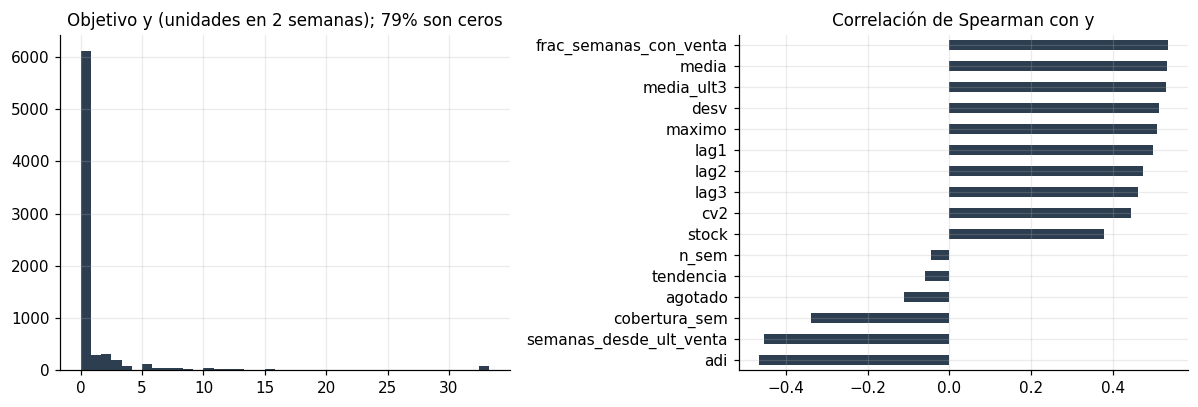

INSIGHT: las variables más asociadas al objetivo son frac_semanas_con_venta, media, media_ult3. El 79% de los casos tiene y = 0: la mayor parte del error vendrá de acertar CUÁNDO ocurre una venta, no solo cuánto.


In [10]:
# ---- Distribución del objetivo y relación de las variables con él ----
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(dataset["y"].clip(upper=dataset["y"].quantile(.99)), bins=40, color="#2C3E50")
ax[0].set_title(f"Objetivo y (unidades en {H} semanas); {(dataset['y'] == 0).mean():.0%} son ceros")
corr = dataset[NUM_COLS + ["y"]].corr(method="spearman")["y"].drop("y").sort_values()
corr.plot.barh(ax=ax[1], color="#2C3E50"); ax[1].set_title("Correlación de Spearman con y")
plt.tight_layout(); plt.show()
print(f"INSIGHT: las variables más asociadas al objetivo son {', '.join(corr.abs().sort_values(ascending=False).index[:3])}. "
      f"El {(dataset['y'] == 0).mean():.0%} de los casos tiene y = 0: la mayor parte del error vendrá de acertar CUÁNDO ocurre una venta, no solo cuánto.")

## 4. Entrenamiento con split train / validación

Los datos son una serie de tiempo: **un split aleatorio mezclaría futuro y pasado** y daría métricas falsamente buenas.
Se divide por *origen temporal* con una **purga** para evitar solapes (el objetivo de un origen T usa las semanas T y T+1;
un origen vecino compartiría una semana con el siguiente):

| Partición | Orígenes | Uso |
|---|---|---|
| **Test** (hold-out final) | T máximo | se usa **una sola vez**, al final, para confirmar la elección |
| *Purga* | T_test − 1 | se descarta: su objetivo comparte la semana T_test con el test |
| **Pool** (train + validación) | T ≤ T_test − 2 | donde se entrena, se valida y se optimiza |
| ↳ **Validación** | último origen del pool | evalúa los modelos base |
| ↳ **Train base** | T ≤ T_validación − 2 | entrena los modelos base |

In [11]:
# ---- Split temporal ----
part = dividir_por_origen(dataset, H)
test, pool, train_base, valid = part["test"], part["pool"], part["train_base"], part["validacion"]
COLS_X = FEATURES + COLS_BL          # las columnas bl_* solo las usan los baselines; los modelos de ML usan FEATURES
print(pd.DataFrame({"orígenes T": [sorted(train_base["T"].unique()), part["t_val"], part["t_test"] - 1, part["t_test"]],
                    "filas": [len(train_base), len(valid), len(dataset[dataset["T"] == part["t_test"] - 1]), len(test)]},
                   index=["train base", "validación", "purga (descartado)", "test (no tocar)"]).to_string())
assert train_base["T"].max() + H <= valid["T"].min() and pool["T"].max() + H <= test["T"].min(), "hay solape entre particiones"
print("OK: ninguna fila de entrenamiento tiene un objetivo que se solape con la partición siguiente.")

                                       orígenes T  filas
train base          [3, 4, 5, 6, 7, 8, 9, 10, 11]   5301
validación                                     13    592
purga (descartado)                             14    592
test (no tocar)                                15    592
OK: ninguna fila de entrenamiento tiene un objetivo que se solape con la partición siguiente.


In [12]:
# ---- Modelos base (hiperparámetros por defecto) vs baselines, entrenando en train base y evaluando en validación ----
def evaluar(est, entrena, valida):
    est = M.clone(est).fit(entrena[COLS_X], entrena["y"])
    return np.clip(est.predict(valida[COLS_X]), 0, None)

base_modelos = {
    "Croston (baseline)": M.BaselineColumna("bl_croston"),
    "SBA (baseline)": M.BaselineColumna("bl_sba"),
    "TSB (baseline)": M.BaselineColumna("bl_tsb"),
    "Media móvil 4 sem (baseline)": M.BaselineColumna("bl_ma4"),
    "Baseline por segmento ADI/CV²": M.BaselinePorSegmento(),
    "Regresión lineal": M.pipe(M.LinearRegression()),
    "Ridge (alpha=1)": M.pipe(M.Ridge(alpha=1.0)),
    "Random Forest": M.pipe(M.RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    "XGBoost": M.pipe(M.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=SEED, n_jobs=-1)),
}
preds_val = {k: evaluar(m, train_base, valid) for k, m in base_modelos.items()}
tabla_base = tabla_metricas(valid["y"].to_numpy(), preds_val).sort_values("WAPE")
print(f"Validación (T={part['t_val']}, {len(valid)} códigos), modelos sin optimizar:")
display(tabla_base)
mejor_base = tabla_base.index[0]
print(f"INSIGHT: el menor WAPE sin optimizar es '{mejor_base}' ({tabla_base.iloc[0]['WAPE']:.3f}). "
      f"El mejor modelo de ML sin tunear ({tabla_base.loc[['Regresión lineal','Ridge (alpha=1)','Random Forest','XGBoost']].sort_values('WAPE').index[0]}) "
      f"difiere {tabla_base.loc[['Regresión lineal','Ridge (alpha=1)','Random Forest','XGBoost']]['WAPE'].min() - tabla_base.filter(like='baseline', axis=0)['WAPE'].min():+.3f} de WAPE del mejor baseline clásico (negativo = mejor que el baseline).")

Validación (T=13, 592 códigos), modelos sin optimizar:


,WAPE,sesgo,faltante,exceso,cobertura
XGBoost,0.808,-0.053,0.431,0.378,0.288
TSB (baseline),0.824,0.056,0.384,0.440,0.351
Regresión lineal,0.826,0.022,0.402,0.424,0.351
Ridge (alpha=1),0.826,0.022,0.402,0.424,0.360
Random Forest,0.827,-0.009,0.418,0.409,0.351
Media móvil 4 sem (baseline),0.881,0.044,0.418,0.463,0.333
Baseline por segmento ADI/CV²,0.902,0.085,0.409,0.493,0.324
SBA (baseline),0.904,0.202,0.351,0.553,0.387
Croston (baseline),0.964,0.335,0.315,0.650,0.477


INSIGHT: el menor WAPE sin optimizar es 'XGBoost' (0.808). El mejor modelo de ML sin tunear (XGBoost) difiere -0.016 de WAPE del mejor baseline clásico (negativo = mejor que el baseline).


## 5. Optimización de hiperparámetros

Se optimiza cada familia de ML sobre el **pool** con **validación cruzada temporal** (`SplitPorOrigen`): cada fold valida
en un origen y entrena solo con orígenes anteriores (con purga). El criterio es **−WAPE**.

* **Ridge** y **Random Forest** → `GridSearchCV` (espacios pequeños y discretos: se recorren completos).
* **XGBoost** → `RandomizedSearchCV` con 40 combinaciones (espacio grande y continuo: el muestreo aleatorio es más eficiente
  que una malla). Incluye `objective="reg:absoluteerror"`, porque WAPE es un error absoluto y entrenar con la misma pérdida
  que se evalúa suele funcionar mejor con demanda de colas largas.

El número de folds temporales depende de las semanas disponibles (se imprime abajo); con pocas semanas son pocos, y se declara como limitación. La semilla fija el resultado.

Folds temporales: 9 -> (filas train, filas validación): [(589, 589), (1178, 589), (1767, 589), (2356, 589), (2945, 589), (3534, 589), (4123, 589), (4712, 589), (5301, 592)]



Ridge         [grid  ] mejor WAPE CV = 0.874 | {'modelo__alpha': 1000}


RandomForest  [grid  ] mejor WAPE CV = 0.877 | {'modelo__max_depth': None, 'modelo__max_features': 1.0, 'modelo__min_samples_leaf': 5}


XGBoost       [random] mejor WAPE CV = 0.748 | {'modelo__colsample_bytree': np.float64(0.7593953108716831), 'modelo__learning_rate': np.float64(0.08215779086695435), 'modelo__max_depth': 2, 'modelo__min_child_weight': 3, 'modelo__n_estimators': 151, 'modelo__objective': 'reg:absoluteerror', 'modelo__reg_lambda': np.float64(0.37962833053422157), 'modelo__subsample': np.float64(0.7988994023569542)}

Top 5 combinaciones de XGBoost:


,WAPE_CV,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,objective,reg_lambda,subsample
21,0.748,0.759,0.082,2,3,151,reg:absoluteerror,0.380,0.799
12,0.751,0.957,0.128,5,3,132,reg:absoluteerror,0.713,0.868
17,0.752,0.965,0.113,2,1,233,reg:absoluteerror,7.068,0.675
8,0.753,0.970,0.146,5,1,289,reg:absoluteerror,8.776,0.899
34,0.760,0.784,0.013,4,3,474,reg:absoluteerror,0.364,0.989


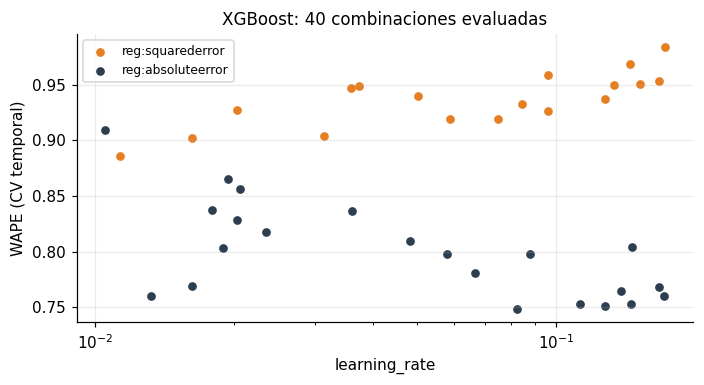

In [13]:
# ---- GridSearchCV / RandomizedSearchCV con validación temporal ----
X_pool, y_pool = pool[COLS_X], pool["y"]
cv = M.SplitPorOrigen(pool["T"].to_numpy(), h=H)
print(f"Folds temporales: {cv.get_n_splits()} -> (filas train, filas validación): {[(len(a), len(b)) for a, b in cv.split()]}\n")
busquedas = M.buscar_hiperparametros(X_pool, y_pool, cv, seed=SEED, n_iter=40)

# mejores 5 combinaciones de XGBoost
r = pd.DataFrame(busquedas["XGBoost"].cv_results_)
r["WAPE_CV"] = -r["mean_test_score"]
cols_p = [c for c in r.columns if c.startswith("param_")]
print("\nTop 5 combinaciones de XGBoost:")
display(r.sort_values("WAPE_CV").head(5)[["WAPE_CV"] + cols_p].rename(columns=lambda c: c.replace("param_modelo__", "")))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for obj, c in zip(["reg:squarederror", "reg:absoluteerror"], ["#E67E22", "#2C3E50"]):
    g = r[r["param_modelo__objective"] == obj]
    ax.scatter(g["param_modelo__learning_rate"].astype(float), g["WAPE_CV"], color=c, label=obj, s=22)
ax.set_xscale("log"); ax.set_xlabel("learning_rate"); ax.set_ylabel("WAPE (CV temporal)")
ax.set_title("XGBoost: 40 combinaciones evaluadas"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Selección del modelo

Se comparan todos los candidatos con **las mismas predicciones fuera de muestra** de la CV temporal (cada fila se predice con un
modelo que no la vio). El criterio de selección combina métricas y negocio:

1. **WAPE de CV** como métrica principal.
2. **Regla de parsimonia**: entre los modelos cuyo WAPE está a ≤ 0,02 del mínimo (diferencia que con tan pocos folds no es distinguible del
   azar) se elige el **más simple** — más fácil de mantener, explicar y auditar por el equipo de compras.
3. **Sesgo / faltante**: se revisa que no subestime de forma sistemática (riesgo de quiebre).
4. El **test** (origen final, nunca usado para elegir) se mira al final solo para confirmar.

También se incluye un **modelo híbrido**: ML en los códigos de rotación alta/media-alta y el baseline por segmento en el resto,
porque en códigos de venta espaciada no hay señal que ML pueda aprender con tan poca historia.

In [14]:
# ---- Candidatos y predicciones fuera de muestra (CV temporal) ----
arboles = {k: v for k, v in busquedas.items() if k in ("RandomForest", "XGBoost")}
mejor_arbol = max(arboles, key=lambda k: arboles[k].best_score_)
mejor_ml = max(busquedas, key=lambda k: busquedas[k].best_score_)

candidatos = {
    "Croston": M.BaselineColumna("bl_croston"),
    "SBA": M.BaselineColumna("bl_sba"),
    "TSB": M.BaselineColumna("bl_tsb"),
    "Baseline por segmento": M.BaselinePorSegmento(),
    "Regresión lineal": M.pipe(M.LinearRegression()),
    "Ridge (opt.)": busquedas["Ridge"].best_estimator_,
    "Random Forest (opt.)": busquedas["RandomForest"].best_estimator_,
    "XGBoost (opt.)": busquedas["XGBoost"].best_estimator_,
    f"Híbrido ({mejor_arbol} alta rotación + baseline)": M.HibridoRotacion(arboles[mejor_arbol].best_estimator_, M.BaselinePorSegmento()),
}
COMPLEJIDAD = {"Croston": 1, "SBA": 1, "TSB": 1, "Baseline por segmento": 2, "Regresión lineal": 3, "Ridge (opt.)": 3,
               "Random Forest (opt.)": 4, "XGBoost (opt.)": 4}
COMPLEJIDAD.update({k: 5 for k in candidatos if k.startswith("Híbrido")})

oof = {k: M.predicciones_fuera_de_muestra(m, X_pool, y_pool, cv) for k, m in candidatos.items()}
tabla_cv = pd.DataFrame({k: resumen(o["real"], o["pred"]) for k, o in oof.items()}).T
tabla_cv["complejidad"] = pd.Series(COMPLEJIDAD)
orig_fold = pool["T"].reindex(oof["Croston"]["idx"]).to_numpy()
for v in sorted(set(orig_fold)):
    tabla_cv[f"WAPE T={v}"] = {k: wape(o.loc[orig_fold == v, "real"], o.loc[orig_fold == v, "pred"]) for k, o in oof.items()}
tabla_cv = tabla_cv.sort_values("WAPE")
print("Validación cruzada temporal (predicciones fuera de muestra):")
display(tabla_cv)

# ---- Regla de selección: parsimonia dentro de la tolerancia de WAPE ----
TOL = 0.02
minimo = tabla_cv["WAPE"].min()
elegibles = tabla_cv[tabla_cv["WAPE"] <= minimo + TOL]
elegido = elegibles.sort_values(["complejidad", "WAPE"]).index[0]
print(f"WAPE mínimo en CV: {minimo:.3f} ({tabla_cv['WAPE'].idxmin()}). Elegibles (≤ {minimo + TOL:.3f}): {list(elegibles.index)}")
print(f"==> MODELO ELEGIDO: {elegido} | WAPE CV {tabla_cv.loc[elegido, 'WAPE']:.3f} | sesgo {tabla_cv.loc[elegido, 'sesgo']:+.1%} "
      f"| faltante {tabla_cv.loc[elegido, 'faltante']:.1%} | exceso {tabla_cv.loc[elegido, 'exceso']:.1%}")
if abs(tabla_cv.loc[elegido, "sesgo"]) > 0.15:
    print("AVISO: el sesgo supera ±15%; conviene calibrar o usar el escenario prudente al pedir.")

Validación cruzada temporal (predicciones fuera de muestra):


,WAPE,sesgo,faltante,exceso,cobertura,complejidad,WAPE T=5,WAPE T=6,WAPE T=7,WAPE T=8,WAPE T=9,WAPE T=10,WAPE T=11,WAPE T=12,WAPE T=13
XGBoost (opt.),0.748,-0.390,0.569,0.179,0.146,4,0.753,0.810,0.747,0.766,0.727,0.771,0.758,0.673,0.727
Híbrido (XGBoost alta rotación + baseline),0.781,-0.216,0.499,0.282,0.219,5,0.826,0.828,0.753,0.801,0.767,0.817,0.796,0.715,0.726
TSB,0.851,0.035,0.408,0.443,0.318,1,0.876,0.933,0.830,0.822,0.789,0.919,0.940,0.750,0.824
Baseline por segmento,0.870,0.030,0.420,0.450,0.328,2,0.874,0.940,0.755,0.821,0.829,0.962,0.984,0.806,0.902
Ridge (opt.),0.871,-0.020,0.445,0.425,0.335,3,0.755,0.858,0.845,0.897,0.917,1.030,0.966,0.776,0.824
Random Forest (opt.),0.874,0.038,0.418,0.456,0.321,4,0.898,0.904,0.810,0.881,0.875,0.986,0.965,0.777,0.797
SBA,0.975,0.167,0.404,0.571,0.340,1,1.050,1.100,0.954,0.911,0.905,1.051,1.058,0.856,0.904
Croston,1.033,0.297,0.368,0.665,0.374,1,1.125,1.154,0.988,0.959,0.953,1.117,1.144,0.917,0.964
Regresión lineal,1.222,0.399,0.412,0.811,0.365,3,3.381,1.055,0.889,0.903,0.950,1.072,1.025,0.822,0.826


WAPE mínimo en CV: 0.748 (XGBoost (opt.)). Elegibles (≤ 0.768): ['XGBoost (opt.)']
==> MODELO ELEGIDO: XGBoost (opt.) | WAPE CV 0.748 | sesgo -39.0% | faltante 56.9% | exceso 17.9%
AVISO: el sesgo supera ±15%; conviene calibrar o usar el escenario prudente al pedir.


,filas,unidades reales,Baseline por segmento,XGBoost (opt.)
rotación,,,,
sin_ventas,2950,499.000,1.000,1.182
baja,592,290.000,1.277,1.116
media-baja,588,459.000,1.377,1.087
media-alta,584,958.000,1.375,1.036
alta,590,"6,457.000",0.730,0.631


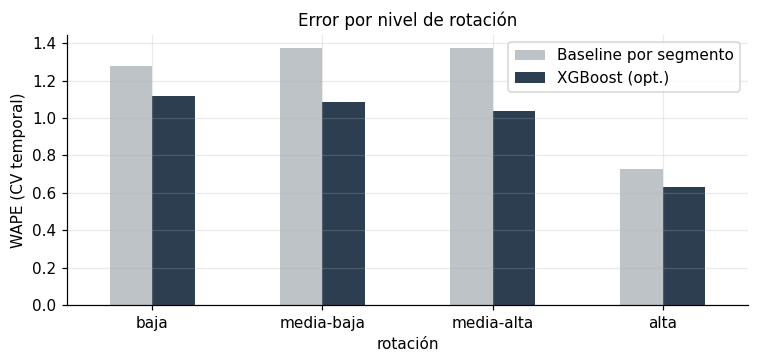

INSIGHT: XGBoost (opt.) mejora al baseline sobre todo en la rotación 'media-alta' (+0.339 de WAPE) y rinde igual o mejor en 'alta' (+0.099). Esa es la base del modelo híbrido.


In [15]:
# ---- ¿Dónde gana cada enfoque? WAPE por nivel de rotación (predicciones fuera de muestra) ----
NOMBRE_CAND = {"RandomForest": "Random Forest (opt.)", "XGBoost": "XGBoost (opt.)", "Ridge": "Ridge (opt.)"}
ml_ref = NOMBRE_CAND[mejor_ml]            # mejor ML optimizado por CV (referencia para comparar)
ml_arbol = NOMBRE_CAND[mejor_arbol]       # el modelo de árboles que usa el híbrido
rot_oof = pool["rotacion"].reindex(oof[ml_arbol]["idx"]).to_numpy()
orden_rot = ["sin_ventas"] + ROT_ETQ
filas = []
for r_ in orden_rot:
    m = rot_oof == r_
    if m.sum() == 0:
        continue
    fila = {"rotación": r_, "filas": int(m.sum()), "unidades reales": oof[ml_arbol].loc[m, "real"].sum()}
    for k in ("Baseline por segmento", ml_arbol):
        fila[k] = wape(oof[k].loc[m, "real"], oof[k].loc[m, "pred"])
    filas.append(fila)
por_rot = pd.DataFrame(filas).set_index("rotación")
display(por_rot)
fig, ax = plt.subplots(figsize=(7, 3.4))
por_rot.loc[[r_ for r_ in ROT_ETQ if r_ in por_rot.index], ["Baseline por segmento", ml_arbol]].plot.bar(ax=ax, color=["#BDC3C7", "#2C3E50"], rot=0)
ax.set_ylabel("WAPE (CV temporal)"); ax.set_title("Error por nivel de rotación"); plt.tight_layout(); plt.show()
dif = (por_rot["Baseline por segmento"] - por_rot[ml_arbol]).drop("sin_ventas", errors="ignore")
if dif.max() > 0.02:
    print(f"INSIGHT: {ml_arbol} mejora al baseline sobre todo en la rotación '{dif.idxmax()}' ({dif.max():+.3f} de WAPE) y rinde "
          f"{'peor' if dif.min() < 0 else 'igual o mejor'} en '{dif.idxmin()}' ({dif.min():+.3f}). Esa es la base del modelo híbrido.")
else:
    print(f"INSIGHT: {ml_arbol} no mejora al baseline de forma material en ninguna rotación (mayor ventaja {dif.max():+.3f} de WAPE en '{dif.idxmax()}'); "
          "el híbrido no aporta valor con estos datos. Casi todo el error se concentra en las rotaciones bajas, donde ningún modelo acierta.")

TEST (T=15, 592 códigos, 1027 unidades reales):


,WAPE,sesgo,faltante,exceso,cobertura,WAPE CV
XGBoost (opt.),0.702,-0.523,0.613,0.089,0.152,0.748
Híbrido (XGBoost alta rotación + baseline),0.728,-0.405,0.566,0.162,0.170,0.781
Baseline por segmento,0.730,-0.081,0.406,0.324,0.286,0.870
TSB,0.745,-0.115,0.430,0.315,0.286,0.851
Regresión lineal,0.776,-0.132,0.454,0.322,0.277,1.222
Ridge (opt.),0.795,-0.140,0.468,0.327,0.286,0.871
Random Forest (opt.),0.810,-0.145,0.477,0.332,0.286,0.874
SBA,0.899,-0.007,0.453,0.446,0.304,0.975
Croston,0.921,0.103,0.409,0.512,0.321,1.033



Elegido 'XGBoost (opt.)': WAPE test 0.702 (IC95% bootstrap 0.621–0.799).
WAPE(Baseline por segmento) − WAPE(elegido) en test: +0.034 (IC95% -0.060 a +0.159); positivo = el elegido es mejor -> la diferencia NO es distinguible de cero (el bootstrap solo captura la variación entre códigos, no entre periodos).


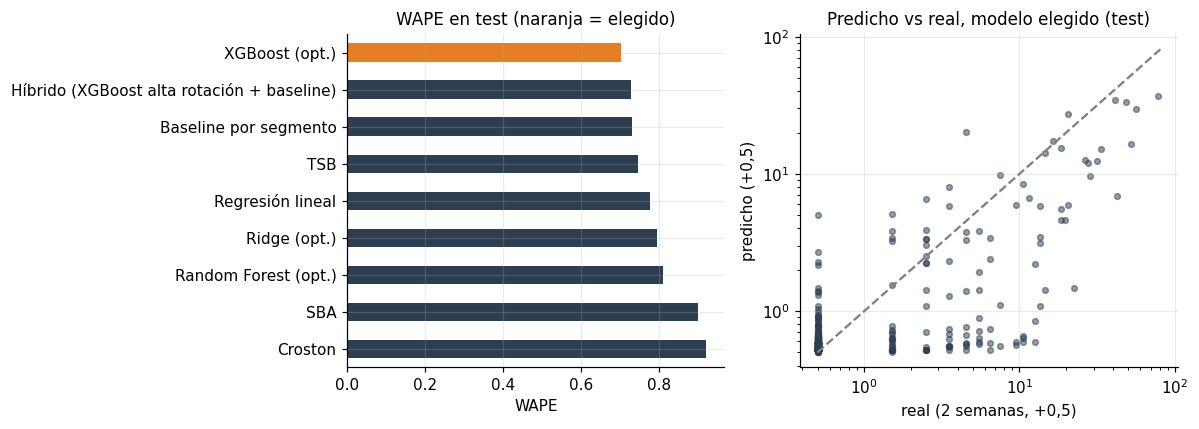

In [16]:
# ---- Confirmación en TEST (origen final, usado una sola vez) ----
preds_test, tabla_test = {}, None
for k, m in candidatos.items():
    est = M.clone(m).fit(X_pool, y_pool)
    preds_test[k] = np.clip(est.predict(test[COLS_X]), 0, None)
tabla_test = tabla_metricas(test["y"].to_numpy(), preds_test)
tabla_test["WAPE CV"] = tabla_cv["WAPE"]
tabla_test = tabla_test.sort_values("WAPE")
print(f"TEST (T={part['t_test']}, {len(test)} códigos, {test['y'].sum():.0f} unidades reales):")
display(tabla_test)

# intervalo de confianza del WAPE del elegido y de la diferencia contra el baseline (bootstrap por código)
rng = np.random.default_rng(SEED)
y_t, p_e = test["y"].to_numpy(), preds_test[elegido]
w_e, dif_b = [], []
p_b = preds_test[ml_ref] if elegido != ml_ref else preds_test["Baseline por segmento"]   # rival: mejor ML (o baseline si el ML fue elegido)
nom_b = ml_ref if elegido != ml_ref else "Baseline por segmento"
for _ in range(2000):
    i = rng.integers(0, len(y_t), len(y_t))
    w_e.append(wape(y_t[i], p_e[i])); dif_b.append(wape(y_t[i], p_b[i]) - wape(y_t[i], p_e[i]))
lo, hi = np.nanpercentile(w_e, [2.5, 97.5]); dlo, dhi = np.nanpercentile(dif_b, [2.5, 97.5])
print(f"\nElegido '{elegido}': WAPE test {wape(y_t, p_e):.3f} (IC95% bootstrap {lo:.3f}–{hi:.3f}).")
print(f"WAPE({nom_b}) − WAPE(elegido) en test: {np.nanmean(dif_b):+.3f} (IC95% {dlo:+.3f} a {dhi:+.3f}); positivo = el elegido es mejor -> "
      f"{'la diferencia NO es distinguible de cero' if dlo <= 0 <= dhi else 'diferencia estadísticamente clara'} (el bootstrap solo captura la variación entre códigos, no entre periodos).")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tabla_test["WAPE"].sort_values(ascending=False).plot.barh(ax=ax[0], color=["#E67E22" if i == elegido else "#2C3E50" for i in tabla_test["WAPE"].sort_values(ascending=False).index])
ax[0].set_title("WAPE en test (naranja = elegido)"); ax[0].set_xlabel("WAPE")
lim = max(y_t.max(), p_e.max()) * 1.05
ax[1].scatter(y_t + .5, p_e + .5, s=14, alpha=.5, color="#2C3E50"); ax[1].plot([.5, lim], [.5, lim], "--", color="gray")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("real (2 semanas, +0,5)"); ax[1].set_ylabel("predicho (+0,5)")
ax[1].set_title("Predicho vs real, modelo elegido (test)")
plt.tight_layout(); plt.show()

,Baseline por segmento,XGBoost (opt.)
5,0.874,0.753
6,0.940,0.810
7,0.755,0.747
8,0.821,0.766
9,0.829,0.727
10,0.962,0.771
11,0.984,0.758
12,0.806,0.673
13,0.902,0.727
14,0.918,0.756


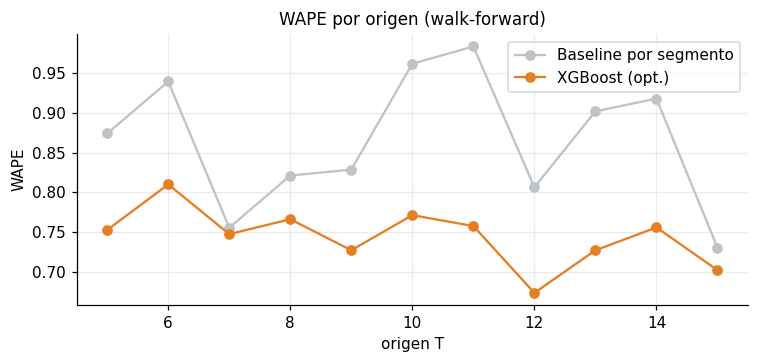

INSIGHT: en 11 de 11 orígenes XGBoost (opt.) supera al baseline por segmento; WAPE medio 0.745 vs 0.866.


In [17]:
# ---- Robustez: evaluación walk-forward en todos los orígenes posibles ----
# (los hiperparámetros se eligieron con los folds finales del pool, por lo que los últimos orígenes son algo optimistas;
#  sirve para ver si el ranking es estable en el tiempo, no como medida final)
comparar = {"Baseline por segmento": candidatos["Baseline por segmento"], elegido: candidatos[elegido], ml_ref: candidatos[ml_ref]}
wf = {}
for v in sorted(dataset["T"].unique()):
    tr = dataset[dataset["T"] <= v - H]
    te = dataset[dataset["T"] == v]
    if len(tr) < 100 or len(te) == 0:
        continue
    wf[v] = {k: wape(te["y"], np.clip(M.clone(m).fit(tr[COLS_X], tr["y"]).predict(te[COLS_X]), 0, None)) for k, m in comparar.items()}
wf = pd.DataFrame(wf).T
display(wf)
ax = wf.plot(marker="o", figsize=(7, 3.4), color=["#BDC3C7", "#E67E22", "#2C3E50"][:wf.shape[1]])
ax.set_xlabel("origen T"); ax.set_ylabel("WAPE"); ax.set_title("WAPE por origen (walk-forward)"); plt.tight_layout(); plt.show()
print(f"INSIGHT: en {int((wf[ml_ref] < wf['Baseline por segmento']).sum())} de {len(wf)} orígenes {ml_ref} supera al baseline por segmento; "
      f"WAPE medio {wf[ml_ref].mean():.3f} vs {wf['Baseline por segmento'].mean():.3f}.")

## 7. Explicabilidad con SHAP

SHAP descompone cada predicción en la contribución de cada variable (valores de Shapley). Se explica el **mejor modelo de árboles**
(menor WAPE de CV entre Random Forest y XGBoost) aunque el modelo elegido sea más simple: es el que se usaría en los códigos de alta
rotación (modelo híbrido) y permite entender **qué señal aprovecha el ML** y qué variables importan al negocio.

Modelo explicado: XGBoost | filas explicadas: 592


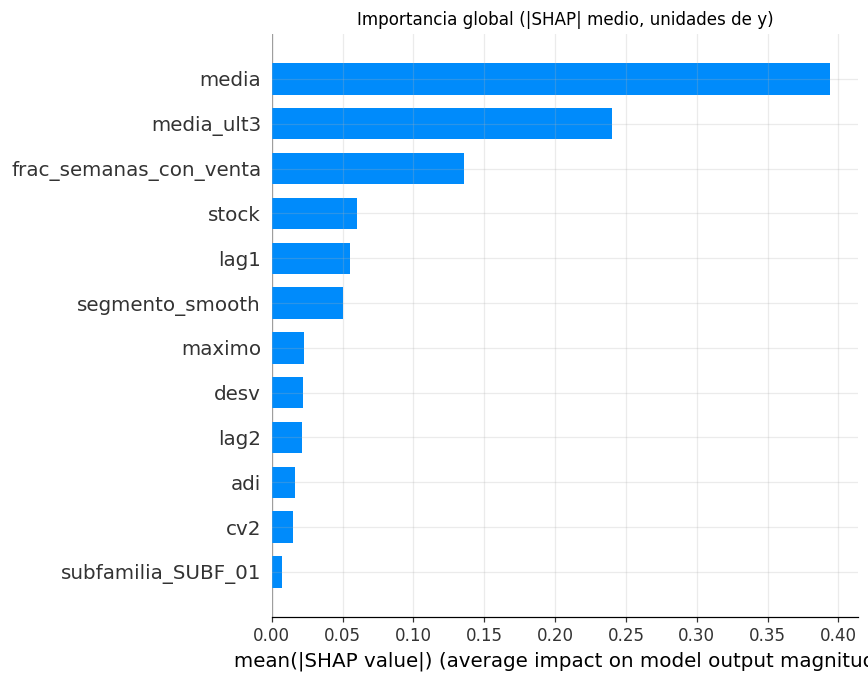

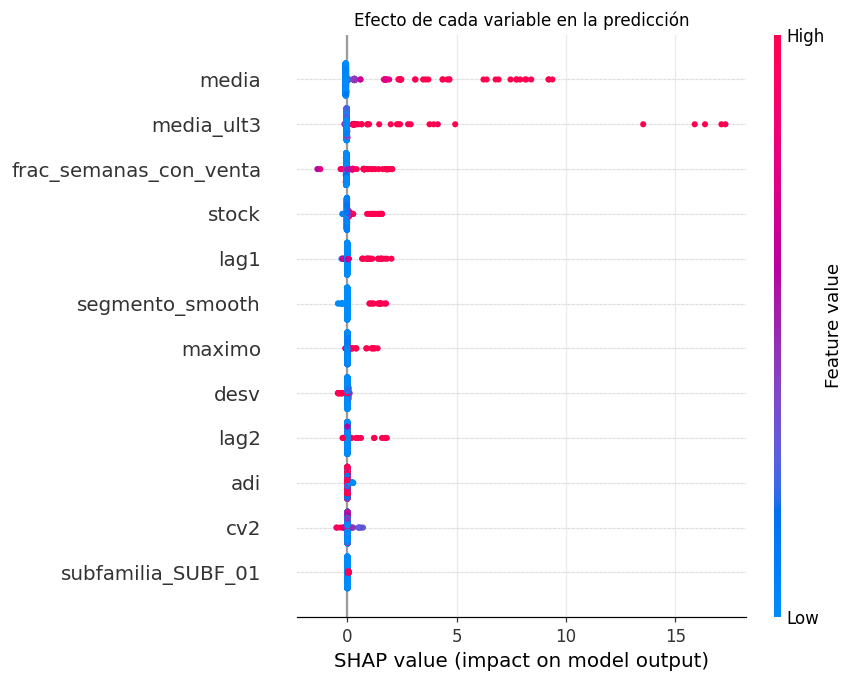

<Figure size 704x528 with 0 Axes>

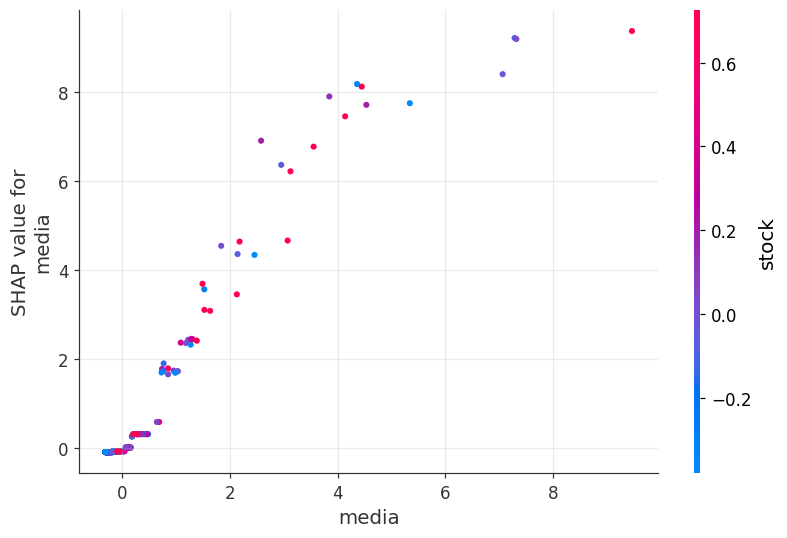

,|SHAP| medio,al aumentar el valor…
variable,,
media,0.394,↑ sube la predicción
media_ult3,0.241,↑ sube la predicción
frac_semanas_con_venta,0.135,↑ sube la predicción
stock,0.060,↑ sube la predicción
lag1,0.055,↑ sube la predicción
segmento_smooth,0.051,categoría


INSIGHT: las variables que más mueven la predicción son media, media_ult3, frac_semanas_con_venta; entre las 39 columnas, las 5 primeras concentran 84% del efecto total.
La variable dominante es el nivel de ventas pasado: el modelo hace, en esencia, lo que un promedio ponderado; coherente con que los baselines sean difíciles de superar con tan poco historial.


In [18]:
# ---- SHAP sobre el mejor modelo de árboles, explicando el test ----
import shap
modelo_shap = arboles[mejor_arbol].best_estimator_          # ya reentrenado con todo el pool por la búsqueda
prep, reg = modelo_shap.named_steps["prep"], modelo_shap.named_steps["modelo"]
Xt = pd.DataFrame(prep.transform(test[COLS_X]), columns=prep.get_feature_names_out(), index=test.index)
sv = shap.TreeExplainer(reg).shap_values(Xt)

# para mostrar valores originales (no estandarizados) en los gráficos de dependencia
Xdisp = Xt.copy()
for c in NUM_COLS:
    Xdisp[c] = test[c].to_numpy()

imp = pd.Series(np.abs(sv).mean(axis=0), index=Xt.columns).sort_values(ascending=False)
print(f"Modelo explicado: {mejor_arbol} | filas explicadas: {len(Xt)}")
plt.figure(); shap.summary_plot(sv, Xt, plot_type="bar", max_display=12, show=False); plt.title("Importancia global (|SHAP| medio, unidades de y)")
plt.tight_layout(); plt.show()
plt.figure(); shap.summary_plot(sv, Xt, max_display=12, show=False); plt.title("Efecto de cada variable en la predicción")
plt.tight_layout(); plt.show()
plt.figure(); shap.dependence_plot(imp.index[0], sv, Xt, display_features=Xdisp, show=False)
plt.tight_layout(); plt.show()

# dirección del efecto de las variables más importantes
filas = []
for f in imp.index[:6]:
    if f in NUM_COLS:
        rho = pd.Series(Xdisp[f].to_numpy()).corr(pd.Series(sv[:, list(Xt.columns).index(f)]), method="spearman")
        filas.append((f, imp[f], "↑ sube la predicción" if rho > 0.2 else ("↓ la baja" if rho < -0.2 else "efecto no monótono")))
    else:
        filas.append((f, imp[f], "categoría"))
resumen_shap = pd.DataFrame(filas, columns=["variable", "|SHAP| medio", "al aumentar el valor…"]).set_index("variable")
display(resumen_shap)
hist_vars = {"lag1", "lag2", "lag3", "media", "media_ult3", "maximo", "desv"}
print(f"INSIGHT: las variables que más mueven la predicción son {', '.join(imp.index[:3])}; "
      f"entre las {len(Xt.columns)} columnas, las 5 primeras concentran {imp.iloc[:5].sum() / imp.sum():.0%} del efecto total.")
if imp.index[0] in hist_vars:
    print("La variable dominante es el nivel de ventas pasado: el modelo hace, en esencia, lo que un promedio ponderado; "
          "coherente con que los baselines sean difíciles de superar con tan poco historial.")
else:
    print("La variable dominante no es el nivel de ventas pasado: el modelo aprovecha otra señal (inventario/categorías); conviene validarla con el negocio.")

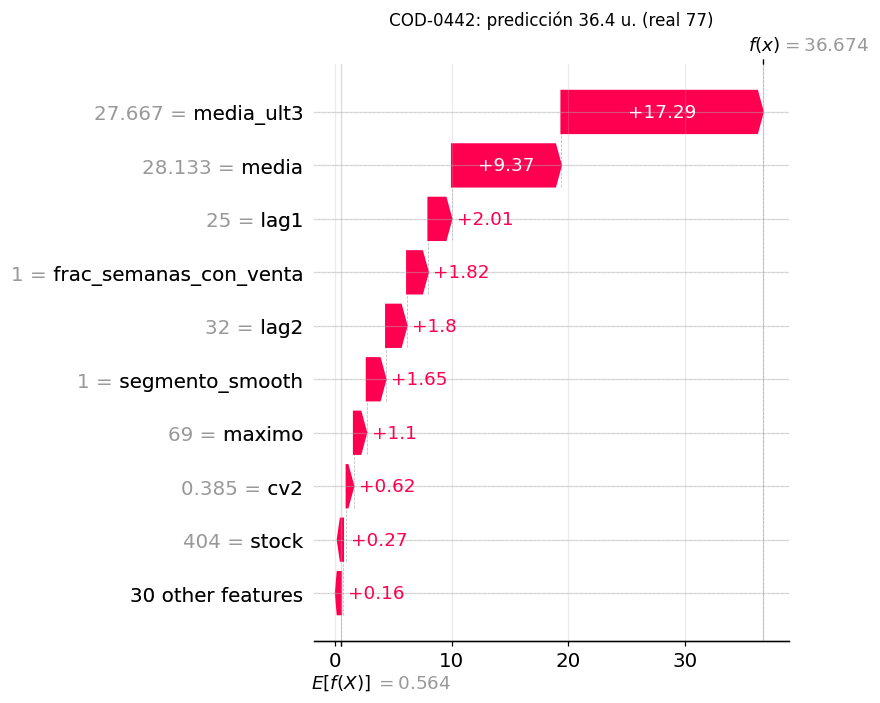

In [19]:
# ---- Explicación de un caso individual: el código de mayor demanda predicha en test ----
i = int(np.argmax(reg.predict(Xt)))
expl = shap.Explanation(values=sv[i], base_values=float(np.ravel(shap.TreeExplainer(reg).expected_value)[0]),
                        data=Xdisp.iloc[i].to_numpy(), feature_names=list(Xt.columns))
shap.plots.waterfall(expl, max_display=10, show=False); plt.title(f"{test.iloc[i]['codigo']}: predicción {reg.predict(Xt)[i]:.1f} u. (real {test.iloc[i]['y']:.0f})")
plt.tight_layout(); plt.show()

## 8. Conclusiones y limitaciones

In [20]:
# ---- Conclusiones calculadas con los resultados de esta ejecución ----
w_el, w_ba = wape(y_t, preds_test[elegido]), wape(y_t, preds_test["Baseline por segmento"])
mejor_test = tabla_test["WAPE"].idxmin()
print(f"""RESULTADOS (datos: {DATA_PATH})
• Problema: regresión de la demanda de {H} semanas por código; métrica WAPE; {dataset['codigo'].nunique()} códigos, {semanas} semanas de historia.
• Modelo elegido por CV temporal + parsimonia: {elegido}
    - WAPE en validación cruzada: {tabla_cv.loc[elegido, 'WAPE']:.3f} | en test: {w_el:.3f} (IC95% {lo:.3f}–{hi:.3f}).
    - Baseline por segmento (Croston/SBA/TSB según segmento): CV {tabla_cv.loc['Baseline por segmento', 'WAPE']:.3f} | test {w_ba:.3f}.
    - Mejor ML optimizado en CV: {ml_ref} (WAPE CV {tabla_cv.loc[ml_ref, 'WAPE']:.3f}, test {wape(y_t, preds_test[ml_ref]):.3f}).
    - Mejor modelo en test: {mejor_test} ({tabla_test.loc[mejor_test, 'WAPE']:.3f}).
• Sesgo del elegido (CV): {tabla_cv.loc[elegido, 'sesgo']:+.1%}; faltante {tabla_cv.loc[elegido, 'faltante']:.1%} y exceso {tabla_cv.loc[elegido, 'exceso']:.1%} de la demanda real.
• SHAP: variables dominantes {', '.join(imp.index[:3])}.
""")
gana_ml = tabla_cv.loc[ml_ref, "WAPE"] < tabla_cv.loc["Baseline por segmento", "WAPE"] - TOL
if mejor_test != elegido:
    print(f"NOTA: en test '{mejor_test}' obtuvo menor WAPE ({tabla_test.loc[mejor_test, 'WAPE']:.3f}) que el elegido ({w_el:.3f}); el test es un único origen y cambiar la "
          "elección a posteriori sería ajustar al test. La decisión se mantiene y se recomienda reevaluar con más semanas.")
ses_el, ses_ba = tabla_cv.loc[elegido, "sesgo"], tabla_cv.loc["Baseline por segmento", "sesgo"]
fal_el, fal_ba = tabla_cv.loc[elegido, "faltante"], tabla_cv.loc["Baseline por segmento", "faltante"]
if gana_ml:
    lectura = (f"el ML ({ml_ref}) mejora al baseline por segmento en validación cruzada temporal "
               f"(WAPE {tabla_cv.loc[ml_ref, 'WAPE']:.3f} vs {tabla_cv.loc['Baseline por segmento', 'WAPE']:.3f}).")
    if elegido == ml_ref:
        lectura += (" En test, con un solo origen, la ventaja " +
                    ("no es distinguible de cero (el IC95% de la diferencia incluye 0)." if dlo <= 0 <= dhi else "es estadísticamente clara."))
    if abs(ses_el) > 0.15:
        lectura += (f" Ojo: el elegido subestima la demanda (sesgo {ses_el:+.0%}; faltante {fal_el:.0%} frente a {fal_ba:.0%} del baseline, sesgo {ses_ba:+.0%}). "
                    "Con tantos ceros, un objetivo de error absoluto tiende a predecir valores cercanos a la mediana (0): baja el WAPE a costa de más quiebres. "
                    "Antes de usarlo para pedir conviene calibrarlo o usar un escenario prudente; el WAPE solo no basta como criterio de negocio.")
    else:
        lectura += " El sesgo es moderado, por lo que puede usarse como apoyo a la decisión de compra."
else:
    lectura = ("el ML NO supera de forma clara al baseline clásico con esta historia. Es un resultado válido y esperable en demanda intermitente "
               "con pocas semanas: se prefiere el modelo más simple y se reserva el ML para los códigos de alta rotación (híbrido), donde sí hay señal.")
print("LECTURA: " + lectura)

RESULTADOS (datos: data/sample_snapshots.csv)
• Problema: regresión de la demanda de 2 semanas por código; métrica WAPE; 592 códigos, 17 semanas de historia.
• Modelo elegido por CV temporal + parsimonia: XGBoost (opt.)
    - WAPE en validación cruzada: 0.748 | en test: 0.702 (IC95% 0.621–0.799).
    - Baseline por segmento (Croston/SBA/TSB según segmento): CV 0.870 | test 0.730.
    - Mejor ML optimizado en CV: XGBoost (opt.) (WAPE CV 0.748, test 0.702).
    - Mejor modelo en test: XGBoost (opt.) (0.702).
• Sesgo del elegido (CV): -39.0%; faltante 56.9% y exceso 17.9% de la demanda real.
• SHAP: variables dominantes media, media_ult3, frac_semanas_con_venta.

LECTURA: el ML (XGBoost (opt.)) mejora al baseline por segmento en validación cruzada temporal (WAPE 0.748 vs 0.870). En test, con un solo origen, la ventaja no es distinguible de cero (el IC95% de la diferencia incluye 0). Ojo: el elegido subestima la demanda (sesgo -39%; faltante 57% frente a 42% del baseline, sesgo +3%). Con t

### Limitaciones (a tener en cuenta antes de usar los resultados)

1. **Historial corto (17 semanas en la muestra real).** Hay pocos orígenes de evaluación (un único origen de test y pocos folds de CV), por lo que las diferencias
   pequeñas de WAPE no son concluyentes; el intervalo bootstrap las dimensiona. Conviene recalcular cada 4 semanas.
2. **El error se mide a 2 semanas.** Mide la estabilidad de la señal por código; **no garantiza** el error a 45 días (lead time) ni a horizontes largos.
3. **No se descuentan pedidos en tránsito** ni se modelan promociones, quiebres de proveedor o estacionalidad anual (no hay un año de datos).
4. **Demanda censurada por quiebres:** un código agotado vende 0 aunque haya demanda. La variable `agotado` ayuda, pero no corrige el sesgo.
5. **Lead time fijo de 45 días** en el análisis de negocio original; no se optimizó como parámetro.
6. **Muestra anonimizada:** los códigos, marcas y subfamilias están enmascarados; las conclusiones sobre productos concretos no aplican al repositorio público.

### Próximos pasos
* Re-entrenar con más semanas y comparar con un horizonte de 4 semanas.
* Pronóstico probabilístico (cuantiles P10–P90) para dimensionar el pedido prudente.
* Medir el impacto en compras: unidades de quiebre y sobrestock evitados frente al método actual.